# 📊 Auditoría y Análisis Exploratorio de Datos (EDA) — Noticias Financieras Multisource (2010–2023)

Este notebook realiza una **auditoría completa de integridad, balance y cobertura temporal** sobre el dataset consolidado de artículos y noticias financieras descargado directamente desde **Cloudflare R2**:
- **Archivo en R2:** `raw/huggingface/multisource_bancos_2010_2023.parquet` (41.6 MB).
- **Universo objetivo:** Los 6 grandes bancos de EE.UU. (`JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`) definidos en `src/shared/tickets.py`.
- **Horizonte temporal:** 14 años completos (**2010 a 2023**).

### Objetivos de la Auditoría:
1. **Verificación de Cobertura Temporal:** Comprobar la eliminación de las lagunas de los datasets anteriores, verificando que no existan años vacíos.
2. **Simetría y Balance entre Bancos:** Cuantificar el volumen y la proporción de noticias para cada entidad bancaria.
3. **Diversidad de Fuentes y Publishers:** Analizar la procedencia multi-fuente (*FNSPID*, *Benzinga*, *SentARL*, *Yahoo Finance*).
4. **Métricas de Texto para Modelos NLP:** Evaluar la longitud de caracteres y conteo de palabras para su posterior procesamiento con **FinBERT / RoBERTa**.

In [11]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config.settings import settings
from dependencies.dependencies import get_storage_repository

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.figsize": (12, 6), "font.size": 11})

storage = get_storage_repository()

async def cargar_dataset(key: str) -> pd.DataFrame:
    """Descarga el payload de R2 y construye el DataFrame optimizando memoria."""
    raw_bytes = await storage.get(key.lstrip("/"))
    return pd.read_parquet(io.BytesIO(raw_bytes))

R2_KEY = "raw/huggingface/multisource_bancos_2010_2023.parquet"

# Top-level await nativo del kernel de Jupyter/IPython
df = await cargar_dataset(R2_KEY)

# Normalización temporal y métricas vectorizadas
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)
df["year"] = df["datetime"].dt.year
df["year_month"] = df["datetime"].dt.to_period("M")

text_series = df["text"].fillna("")
df["char_count"] = text_series.str.len()
df["word_count"] = text_series.str.count(r"\S+")

print(f"✔ Dataset cargado exitosamente: {len(df):,} noticias | {df.shape[1]} columnas")
df.head()

C:\Users\0021824\AppData\Local\Temp\ipykernel_26324\4175634027.py:27: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["year_month"] = df["datetime"].dt.to_period("M")


✔ Dataset cargado exitosamente: 89,846 noticias | 20 columnas


,record_id,ticker,company_name,cik,date,datetime,has_exact_time,market_session,title,article,text,publisher,url,source_dataset,ticker_count,is_multisubject,year,year_month,char_count,word_count
0,6d1aa4379aceef15922739be,BAC,Bank of America Corp /DE/,CIK0000070858,2010-01-01 21:16:00,2010-01-02 02:16:00+00:00,True,afterhours,Stocks may struggle with less government support,Economic data in early January may test recove...,Stocks may struggle with less government suppo...,SentARL,NaN,sentarl_combined,3,True,2010,2010-01,118,19
1,99c6b7c08263e5f129495f9c,JPM,JPMorgan Chase & Co.,CIK0000019617,2010-01-01 21:16:00,2010-01-02 02:16:00+00:00,True,afterhours,Stocks may struggle with less government support,Economic data in early January may test recove...,Stocks may struggle with less government suppo...,SentARL,NaN,sentarl_combined,3,True,2010,2010-01,118,19
2,4d242475ac6db9b6a4521aa0,WFC,Wells Fargo & Company/MN,CIK0000072971,2010-01-01 21:16:00,2010-01-02 02:16:00+00:00,True,afterhours,Stocks may struggle with less government support,Economic data in early January may test recove...,Stocks may struggle with less government suppo...,SentARL,NaN,sentarl_combined,3,True,2010,2010-01,118,19
3,154b135b85deff23dea06d74,GS,Goldman Sachs Group Inc.,CIK0000886982,2010-01-02 07:45:00,2010-01-02 12:45:00+00:00,True,premarket,Preview,A look forward to those events scheduled for n...,Preview\n\nA look forward to those events sche...,SentARL,NaN,sentarl_combined,1,False,2010,2010-01,64,11
4,f43b1b1cecfa1959683eb993,JPM,JPMorgan Chase & Co.,CIK0000019617,2010-01-02 07:45:00,2010-01-02 12:45:00+00:00,True,premarket,How to Bet on Health and Wealth,Why health care and banking are good bets in 2...,How to Bet on Health and Wealth\n\nWhy health ...,SentARL,NaN,sentarl_combined,3,True,2010,2010-01,83,17


## 1. Verificación de Integridad y Cobertura Temporal (2010–2023)

Uno de los principales problemas del dataset original era la existencia de **años enteros con 0 noticias** para bancos clave como JPMorgan Chase (`JPM`) y Bank of America (`BAC`).

Comprobamos la matriz de contingencia anual por banco para verificar la continuidad ininterrumpida de la serie:

=== MATRIZ ANUAL DE NOTICIAS POR BANCO (2010 - 2023) ===


ticker,BAC,C,GS,JPM,MS,WFC,Total
year,,,,,,,
2010,1327,152,1234,1716,1898,543,6870
2011,1161,177,488,1352,1366,387,4931
2012,986,141,477,1697,1165,636,5102
2013,631,154,575,1256,919,639,4174
2014,577,224,355,875,858,462,3351
2015,883,842,307,868,1053,661,4614
2016,977,1067,1204,1212,1131,2527,8118
2017,1063,1279,1500,1015,1222,2241,8320
2018,735,1116,1255,1444,1083,1424,7057


------------------------------------------------------------
✔ CONFIRMACIÓN: ¡Cero lagunas! Todos los bancos tienen cobertura continua todos los años.
------------------------------------------------------------


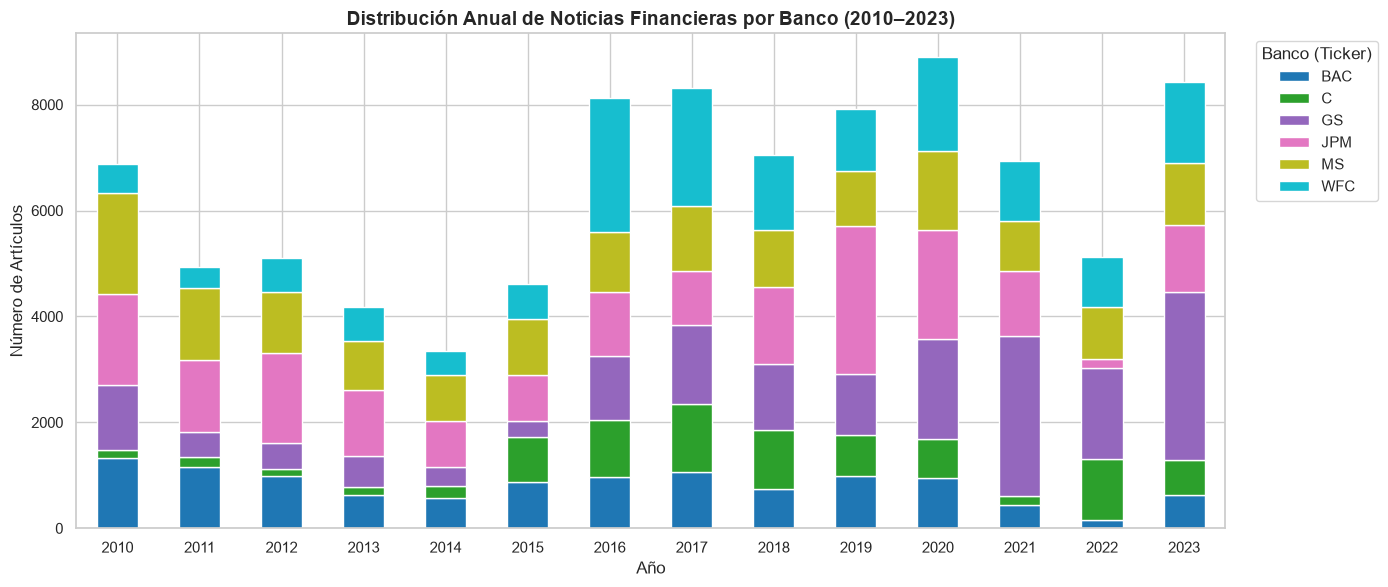

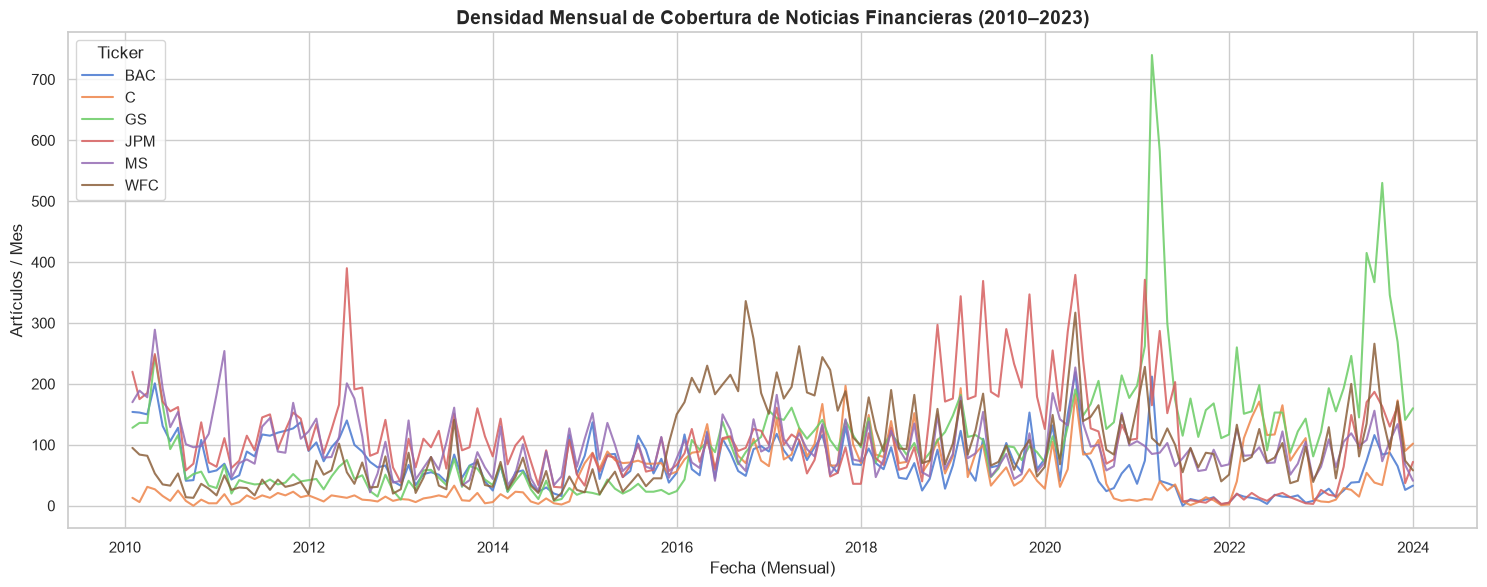

In [12]:
# 1.1 Matriz de contingencia anual
pivot_anual = pd.crosstab(df["year"], df["ticker"], margins=True, margins_name="Total")
print("=== MATRIZ ANUAL DE NOTICIAS POR BANCO (2010 - 2023) ===")
display(pivot_anual)

# Comprobación automática de ceros
pivot_sin_totales = pivot_anual.drop(index="Total", columns="Total")
ceros_detectados = (pivot_sin_totales == 0).sum().sum()
print("-" * 60)
if ceros_detectados == 0:
    print("✔ CONFIRMACIÓN: ¡Cero lagunas! Todos los bancos tienen cobertura continua todos los años.")
else:
    print(f"⚠ ALERTA: Se detectaron {ceros_detectados} celdas con 0 noticias.")
print("-" * 60)

# 1.2 Gráfico de barras apiladas anual
plt.figure(figsize=(14, 6))
anual_por_banco = df.groupby(["year", "ticker"]).size().unstack(fill_value=0)
anual_por_banco.plot(kind="bar", stacked=True, colormap="tab10", ax=plt.gca())
plt.title("Distribución Anual de Noticias Financieras por Banco (2010–2023)", fontsize=14, weight="bold")
plt.xlabel("Año", fontsize=12)
plt.ylabel("Número de Artículos", fontsize=12)
plt.xticks(rotation=0)
plt.legend(title="Banco (Ticker)", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 1.3 Serie temporal mensual continua
plt.figure(figsize=(15, 6))
mensual_por_banco = df.set_index("datetime").groupby(["ticker"]).resample("ME").size().unstack(0, fill_value=0)
for col in mensual_por_banco.columns:
    plt.plot(mensual_por_banco.index, mensual_por_banco[col], label=col, alpha=0.85, linewidth=1.5)

plt.title("Densidad Mensual de Cobertura de Noticias Financieras (2010–2023)", fontsize=14, weight="bold")
plt.xlabel("Fecha (Mensual)", fontsize=12)
plt.ylabel("Artículos / Mes", fontsize=12)
plt.legend(title="Ticker", loc="upper left")
plt.tight_layout()
plt.show()

## 2. Balance y Distribución por Entidad Bancaria (Big 6 Universe)

Analizamos el volumen total y la representatividad porcentual de cada banco dentro del universo estudiado:

,ticker,nombre_banco,cik,total_articulos,porcentaje,palabras_media,primer_articulo,ultimo_articulo
0,JPM,JPMorgan Chase & Co.,CIK0000019617,18953,21.094985,48.7,2010-01-02 02:16:00+00:00,2023-12-30 14:27:42+00:00
1,GS,Goldman Sachs Group Inc.,CIK0000886982,18321,20.391559,345.4,2010-01-02 12:45:00+00:00,2023-12-30 12:41:34+00:00
2,MS,Morgan Stanley,CIK0000895421,16341,18.187788,256.7,2010-01-04 16:44:00+00:00,2023-12-16 22:00:00+00:00
3,WFC,Wells Fargo & Company/MN,CIK0000072971,16075,17.891726,408.3,2010-01-02 02:16:00+00:00,2023-12-30 11:05:25+00:00
4,BAC,Bank of America Corp /DE/,CIK0000070858,11509,12.809697,41.5,2010-01-02 02:16:00+00:00,2023-12-30 13:45:00+00:00
5,C,Citigroup Inc.,CIK0000831001,8647,9.624246,552.3,2010-01-06 20:02:00+00:00,2023-12-30 12:00:22+00:00


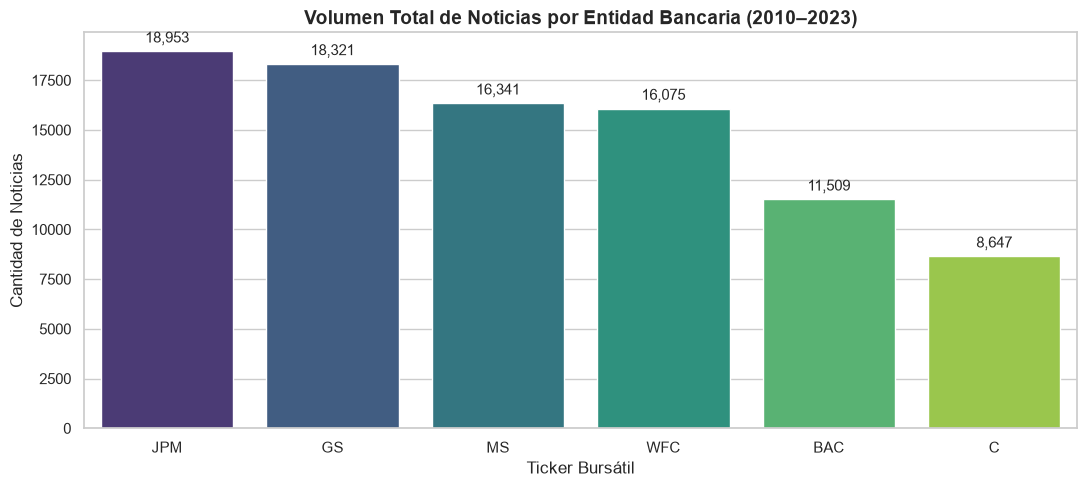

In [13]:
# 2.1 Resumen consolidado por banco
resumen_bancos = df.groupby("ticker").agg(
    nombre_banco=("company_name", "first"),
    cik=("cik", "first"),
    total_articulos=("text", "count"),
    palabras_media=("word_count", "mean"),
    primer_articulo=("datetime", "min"),
    ultimo_articulo=("datetime", "max")
).reset_index()

resumen_bancos["porcentaje"] = (resumen_bancos["total_articulos"] / len(df)) * 100
resumen_bancos["palabras_media"] = resumen_bancos["palabras_media"].round(1)
resumen_bancos = resumen_bancos.sort_values(by="total_articulos", ascending=False).reset_index(drop=True)

display(resumen_bancos[["ticker", "nombre_banco", "cik", "total_articulos", "porcentaje", "palabras_media", "primer_articulo", "ultimo_articulo"]])

# 2.2 Gráfico de barras de volumen por banco
plt.figure(figsize=(11, 5))
palette = sns.color_palette("viridis", len(resumen_bancos))
ax = sns.barplot(
    data=resumen_bancos,
    x="ticker",
    y="total_articulos",
    hue="ticker",
    palette=palette,
    legend=False
)
plt.title("Volumen Total de Noticias por Entidad Bancaria (2010–2023)", fontsize=14, weight="bold")
plt.xlabel("Ticker Bursátil", fontsize=12)
plt.ylabel("Cantidad de Noticias", fontsize=12)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{int(height):,}",
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11,
                xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()

## 3. Desglose por Fuente de Datos y Publishers

Comprobamos la aportación de los diferentes sub-datasets integrados y el ranking de medios emisores de las noticias:

,source_dataset,total_noticias,porcentaje
0,fnspid_news,39702,44.188946
1,sentarl_combined,35884,39.939452
2,yahoo_finance_felixdrinkall,8817,9.813459
3,benzinga_6000stocks,5443,6.058144


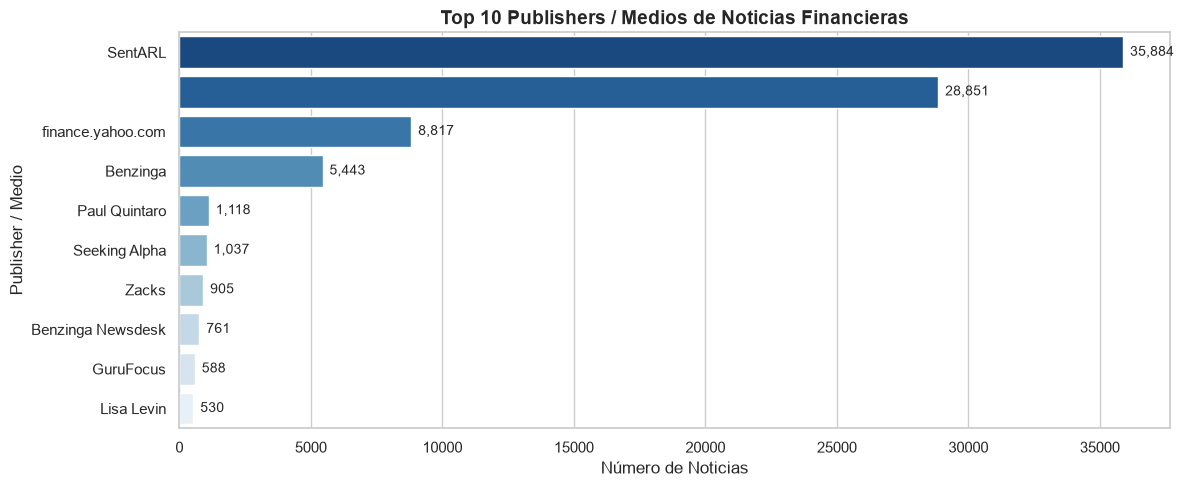

In [14]:
# 3.1 Desglose por sub-dataset de procedencia
fuentes_df = df["source_dataset"].value_counts().reset_index()
fuentes_df.columns = ["source_dataset", "total_noticias"]
fuentes_df["porcentaje"] = (fuentes_df["total_noticias"] / len(df)) * 100
display(fuentes_df)

# 3.2 Top 10 Publishers más frecuentes
top_publishers = df["publisher"].fillna("Desconocido / Syndicated").value_counts().head(10).reset_index()
top_publishers.columns = ["publisher", "total_noticias"]

plt.figure(figsize=(12, 5))
sns.barplot(data=top_publishers, x="total_noticias", y="publisher", hue="publisher", palette="Blues_r", legend=False)
plt.title("Top 10 Publishers / Medios de Noticias Financieras", fontsize=14, weight="bold")
plt.xlabel("Número de Noticias", fontsize=12)
plt.ylabel("Publisher / Medio", fontsize=12)

for p in plt.gca().patches:
    width = p.get_width()
    plt.gca().annotate(f"{int(width):,}",
                       (width, p.get_y() + p.get_height() / 2.),
                       ha='left', va='center', fontsize=10,
                       xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.show()

## 4. Métricas de Texto para Modelado NLP (FinBERT / RoBERTa)

Evaluamos la longitud de texto y el conteo de palabras para determinar si los titulares y artículos encajan dentro del límite estándar de **512 tokens** de las arquitecturas Transformer:

=== ESTADÍSTICAS DEL CONTEO DE PALABRAS (WORD COUNT) ===


,word_count
count,89846.000000
mean,258.893418
std,574.025414
min,1.000000
25%,18.000000
50%,49.000000
75%,339.000000
90%,784.000000
95%,1006.000000
99%,1629.100000


• Noticias breves/titulares (<= 100 palabras): 62.12%
• Noticias extensas (> 512 palabras, requieren chunking): 18.53%


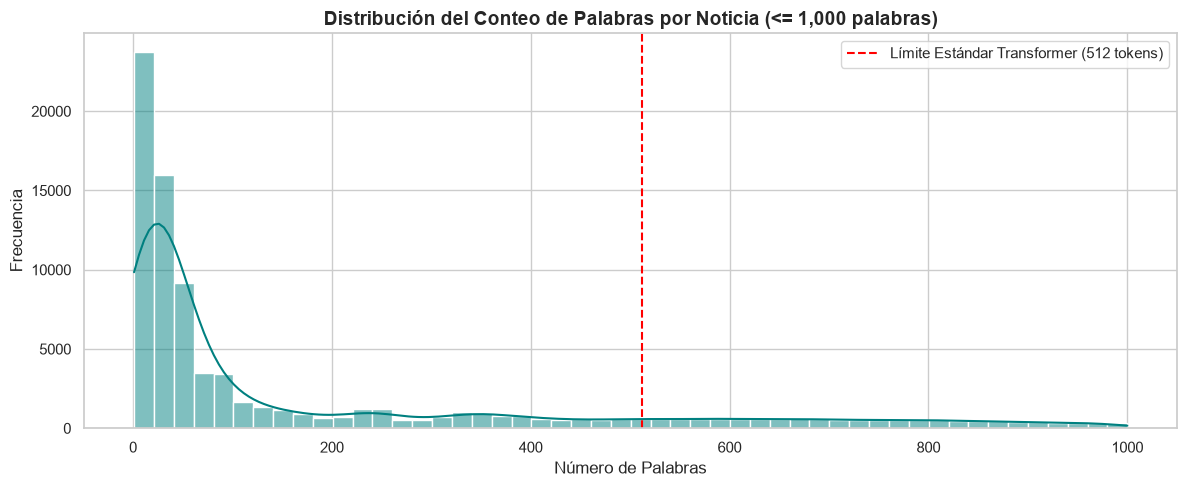

In [15]:
# 4.1 Estadísticas descriptivas de longitud
stats_palabras = df["word_count"].describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
print("=== ESTADÍSTICAS DEL CONTEO DE PALABRAS (WORD COUNT) ===")
display(stats_palabras.to_frame())

# Porcentaje que supera el umbral de 512 palabras (Límite Transformer)
pct_mas_512 = (df["word_count"] > 512).mean() * 100
pct_menos_100 = (df["word_count"] <= 100).mean() * 100
print(f"• Noticias breves/titulares (<= 100 palabras): {pct_menos_100:.2f}%")
print(f"• Noticias extensas (> 512 palabras, requieren chunking): {pct_mas_512:.2f}%")

# 4.2 Histograma de distribución de palabras (truncado a 1,000 para legibilidad)
plt.figure(figsize=(12, 5))
sns.histplot(df[df["word_count"] <= 1000]["word_count"], bins=50, kde=True, color="teal")
plt.axvline(x=512, color="red", linestyle="--", label="Límite Estándar Transformer (512 tokens)")
plt.title("Distribución del Conteo de Palabras por Noticia (<= 1,000 palabras)", fontsize=14, weight="bold")
plt.xlabel("Número de Palabras", fontsize=12)
plt.ylabel("Frecuencia", fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Muestras Cualitativas de Artículos por Banco

Inspección directa de los primeros registros de cada entidad para validar el formato de fecha, el contenido textual y la procedencia:

In [16]:
from shared.tickets import TICKETS


print("=" * 90)
print("MUESTRA CUALITATIVA DE NOTICIAS REALES POR BANCO")
print("=" * 90)

for ticker in TICKETS:
    sample_row = df[df["ticker"] == ticker].iloc[0]
    print(f"\n>>> [{ticker}] {sample_row['company_name']} (CIK: {sample_row['cik']})")
    print(f"    Fecha: {sample_row['date']} | Fuente: {sample_row['source_dataset']} | Publisher: {sample_row['publisher']}")
    print(f"    URL: {sample_row['url']}")
    print(f"    Texto:\n    {sample_row['text'][:250]}...")

MUESTRA CUALITATIVA DE NOTICIAS REALES POR BANCO

>>> [JPM] JPMorgan Chase & Co. (CIK: CIK0000019617)
    Fecha: 2010-01-01 21:16:00 | Fuente: sentarl_combined | Publisher: SentARL
    URL: nan
    Texto:
    Stocks may struggle with less government support

Economic data in early January may test recovery, set tone for 2010....

>>> [BAC] Bank of America Corp /DE/ (CIK: CIK0000070858)
    Fecha: 2010-01-01 21:16:00 | Fuente: sentarl_combined | Publisher: SentARL
    URL: nan
    Texto:
    Stocks may struggle with less government support

Economic data in early January may test recovery, set tone for 2010....

>>> [WFC] Wells Fargo & Company/MN (CIK: CIK0000072971)
    Fecha: 2010-01-01 21:16:00 | Fuente: sentarl_combined | Publisher: SentARL
    URL: nan
    Texto:
    Stocks may struggle with less government support

Economic data in early January may test recovery, set tone for 2010....

>>> [C] Citigroup Inc. (CIK: CIK0000831001)
    Fecha: 2010-01-06 15:02:00 | Fuente: sentarl_co

## 6. Análisis de Contaminación Multisujeto (Multisubject Contamination)

El objetivo de esta sección es identificar el grado de solapamiento de las noticias entre los distintos bancos (tickers). En un entorno financiero, una misma noticia macroeconómica o sectorial puede estar etiquetada simultáneamente para múltiples entidades (por ejemplo, JP Morgan, Bank of America, Goldman Sachs). 

Para la robustez del modelo predictivo del TFM, es crítico cuantificar este ruido y separar:
* **Noticias exclusivas (1 Ticker):** Eventos corporativos que afectan específicamente a una entidad.
* **Noticias replicadas (2+ Tickers):** Ruido de impacto sectorial o general.

Agruparemos el dataset por título (`title`) y fecha exacta (`datetime`) para contar el número de identificadores únicos (`ticker`) asociados a cada publicación.

Análisis de Contaminación Multisujeto (Multisubject Contamination)
Distribución de noticias por cantidad de tickers asociados:
ticker
1    52696
2     8556
3     3030
4     1416
5      897
6      133
Name: count, dtype: int64

Impacto en filas: 58.7% Señal Pura | 41.3% Ruido Multisujeto



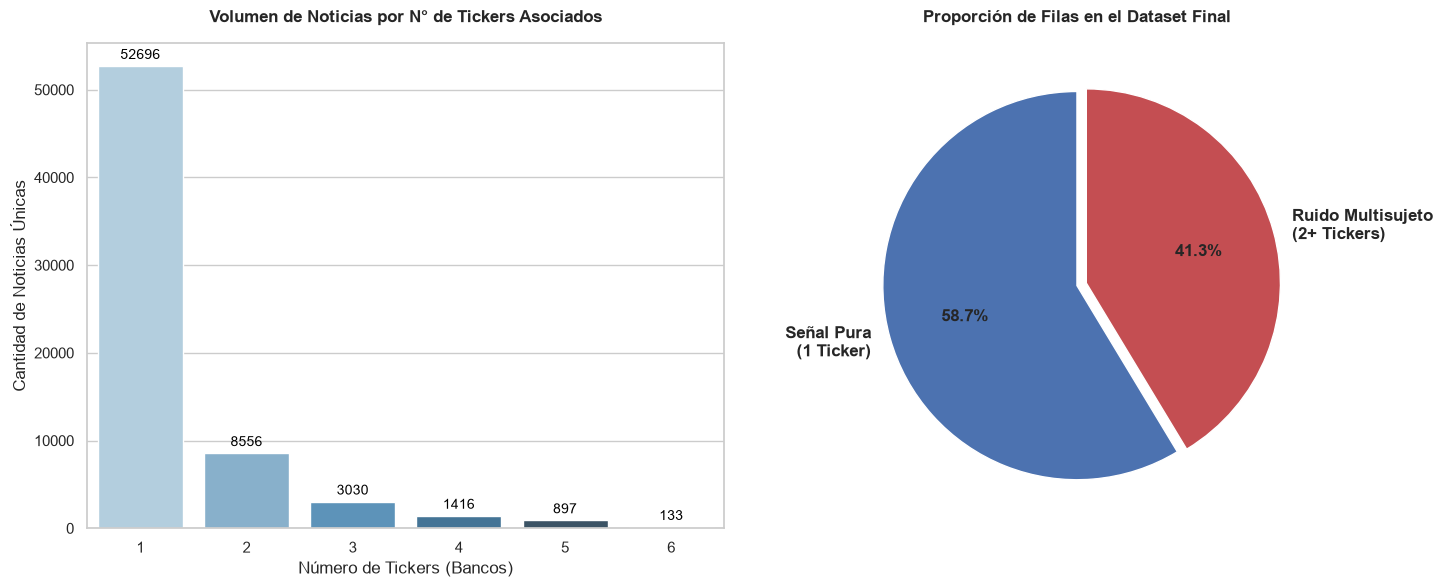

In [17]:
print("=" * 90)
print("Análisis de Contaminación Multisujeto (Multisubject Contamination)")
print("=" * 90)

# 1. Contar cuántos tickers únicos están asociados a la misma noticia
ticker_counts_per_news = df.groupby(['title', 'datetime'])['ticker'].nunique()
distribucion_contaminacion = ticker_counts_per_news.value_counts().sort_index()

# 2. Calcular el impacto estructural (porcentaje real de filas en el dataframe)
df['is_multisubject'] = df.duplicated(subset=['title', 'datetime'], keep=False)
impacto_filas = df['is_multisubject'].value_counts(normalize=True) * 100

# Mostrar los datos por consola
print("Distribución de noticias por cantidad de tickers asociados:")
print(distribucion_contaminacion)
print(f"\nImpacto en filas: {impacto_filas[False]:.1f}% Señal Pura | {impacto_filas[True]:.1f}% Ruido Multisujeto\n")

# 3. Crear el lienzo con dos gráficos (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- GRÁFICO 1 (Izquierda): Barras ---
sns.barplot(
    x=distribucion_contaminacion.index,
    y=distribucion_contaminacion.values,
    ax=axes[0],
    hue=distribucion_contaminacion.index,
    palette="Blues_d",
    legend=False
)
axes[0].set_title("Volumen de Noticias por N° de Tickers Asociados", fontweight='bold', pad=15)
axes[0].set_xlabel("Número de Tickers (Bancos)")
axes[0].set_ylabel("Cantidad de Noticias Únicas")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3, color='black', fontsize=10)

# --- GRÁFICO 2: Tarta ---
labels = ['Señal Pura\n(1 Ticker)', 'Ruido Multisujeto\n(2+ Tickers)']
colores = ['#4C72B0', '#C44E52']

axes[1].pie(
    impacto_filas.sort_index(),
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores,
    explode=[0, 0.05],
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
axes[1].set_title("Proporción de Filas en el Dataset Final", fontweight='bold', pad=15)

# 4. Ajustar y renderizar
plt.tight_layout()
plt.show()

## 6.2. Auditoría Cualitativa y Distribución de la Señal Pura

Antes de avanzar, verificamos físicamente la naturaleza del ruido multisujeto para entender cómo una misma noticia se replica a través de varios tickers. 

Posteriormente, aislamos la **señal pura** (noticias exclusivas de un solo banco, eliminando la contaminación) y analizamos su distribución:
1. **Transversal:** Volumen total de noticias útiles por entidad bancaria.
2. **Longitudinal:** Evolución de la cobertura mediática mes a mes entre 2010 y 2023 para detectar posibles huecos o picos de extracción temporal.

--- 3 EJEMPLOS REALES DE NOTICIAS MULTISUJETO ---
1. Fecha: 2010-03-10 | Replicado en 5 tickers: ['MS', 'BAC', 'C', 'GS', 'JPM']
   Título: "Massive" Volume in Citi $4 Calls

2. Fecha: 2010-08-11 | Replicado en 4 tickers: ['JPM', 'BAC', 'GS', 'MS']
   Título: "Risk-Off" Day: Global Stocks Sharply Lower

3. Fecha: 2010-05-06 | Replicado en 4 tickers: ['GS', 'BAC', 'JPM', 'MS']
   Título: "Whippy" Market as S&P 500 Breaks 50-Day MA



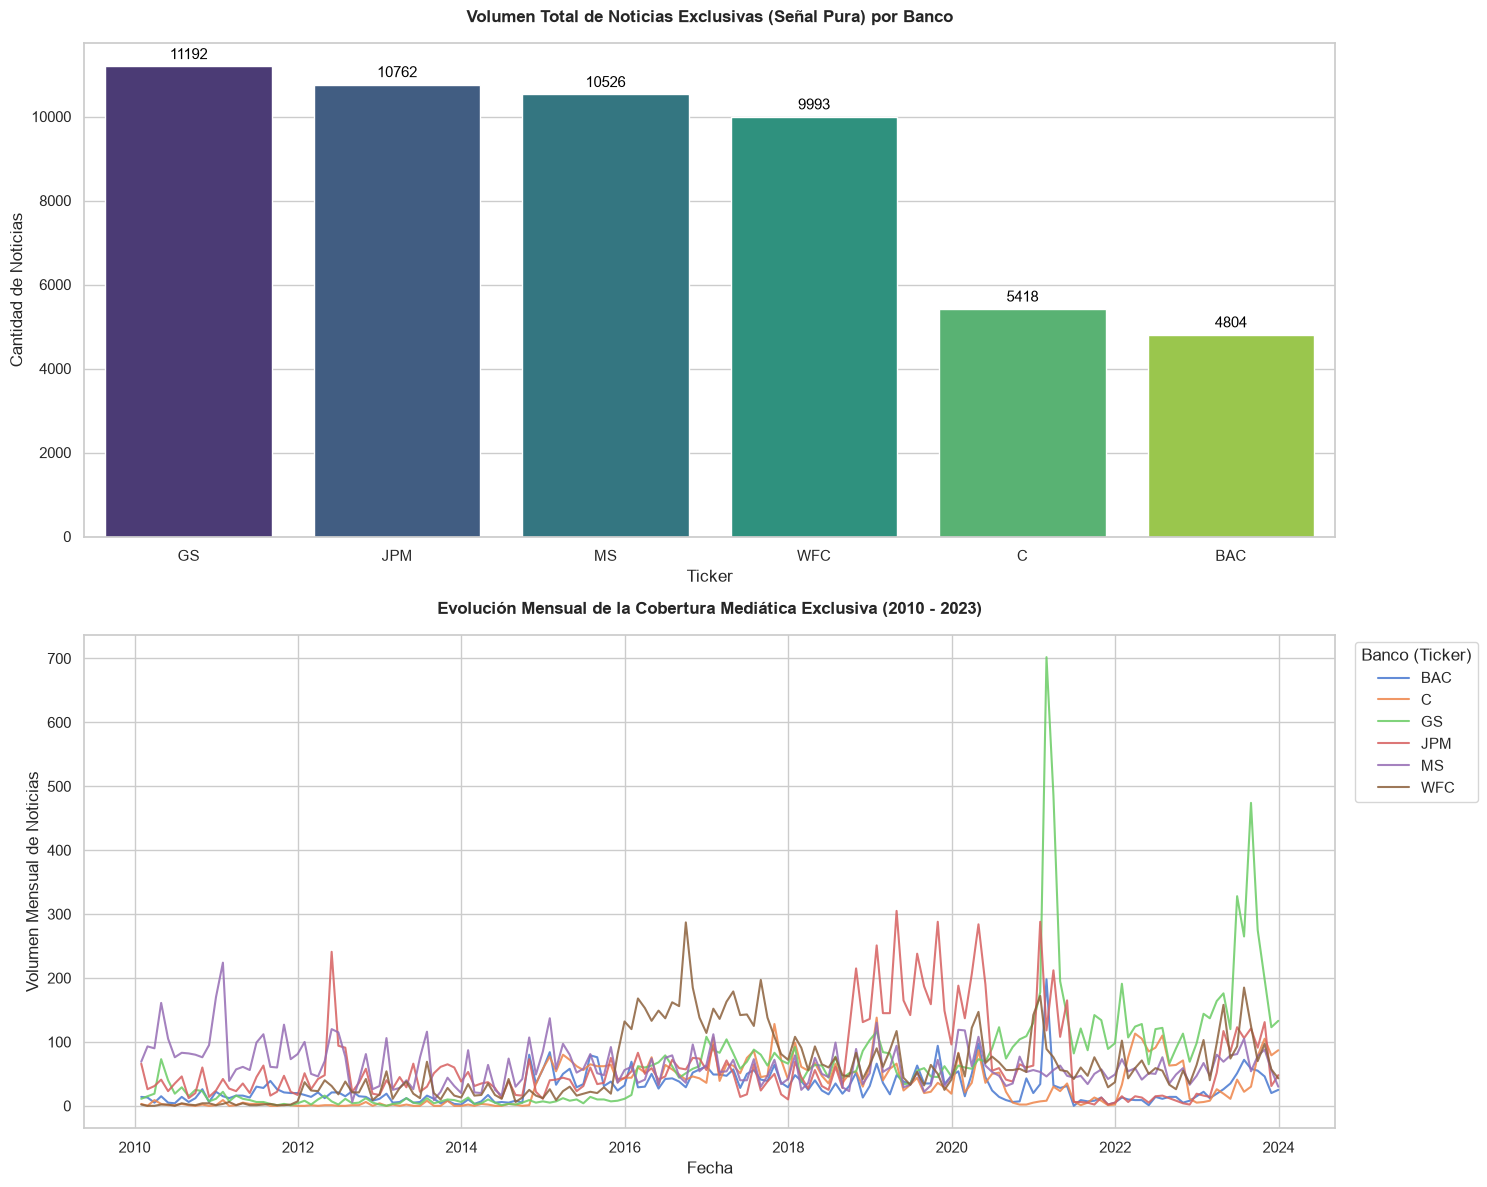

In [18]:
# =============================================================================
# 1. EJEMPLOS DE NOTICIAS MULTISUJETO (RUIDO)
# =============================================================================
print("--- 3 EJEMPLOS REALES DE NOTICIAS MULTISUJETO ---")
# Filtramos el ruido y extraemos 3 noticias únicas distintas
multisujeto_df = df[df['is_multisubject']].sort_values(['title', 'datetime'])
titulos_ejemplo = multisujeto_df['title'].unique()[:3]

for i, titulo in enumerate(titulos_ejemplo, 1):
    ejemplo = multisujeto_df[multisujeto_df['title'] == titulo]
    tickers = ejemplo['ticker'].tolist()
    fecha = ejemplo['datetime'].iloc[0].strftime('%Y-%m-%d')
    print(f"{i}. Fecha: {fecha} | Replicado en {len(tickers)} tickers: {tickers}")
    print(f"   Título: {titulo}\n")



# =============================================================================
# 2. AISLAMIENTO DE SEÑAL Y VISUALIZACIÓN
# =============================================================================
# Descartamos el ruido para ver de qué datos reales dispone el modelo
df_pura = df[~df['is_multisubject']].copy()

# Crear lienzo con 2 filas y 1 columna
fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# --- GRÁFICO A: Distribución por Banco (Barras) ---
conteo_puro = df_pura['ticker'].value_counts()
sns.barplot(
    x=conteo_puro.index,
    y=conteo_puro.values,
    ax=axes[0],
    hue=conteo_puro.index,
    palette="viridis",
    legend=False
)
axes[0].set_title("Volumen Total de Noticias Exclusivas (Señal Pura) por Banco", fontweight='bold', pad=15)
axes[0].set_ylabel("Cantidad de Noticias")
axes[0].set_xlabel("Ticker")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3, color='black', fontsize=11)

# --- GRÁFICO B: Serie Temporal Mensual Continua (Líneas) ---
# Agrupamos usando el snippet exacto, aplicado al dataframe limpio
mensual_por_banco = df_pura.set_index("datetime").groupby("ticker").resample("ME").size().unstack(0, fill_value=0)

for col in mensual_por_banco.columns:
    axes[1].plot(
        mensual_por_banco.index,
        mensual_por_banco[col],
        label=col,
        alpha=0.85,
        linewidth=1.5
    )

axes[1].set_title("Evolución Mensual de la Cobertura Mediática Exclusiva (2010 - 2023)", fontweight='bold', pad=15)
axes[1].set_ylabel("Volumen Mensual de Noticias")
axes[1].set_xlabel("Fecha")
# Movemos la leyenda fuera del gráfico para que no tape las líneas
axes[1].legend(title="Banco (Ticker)", bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()

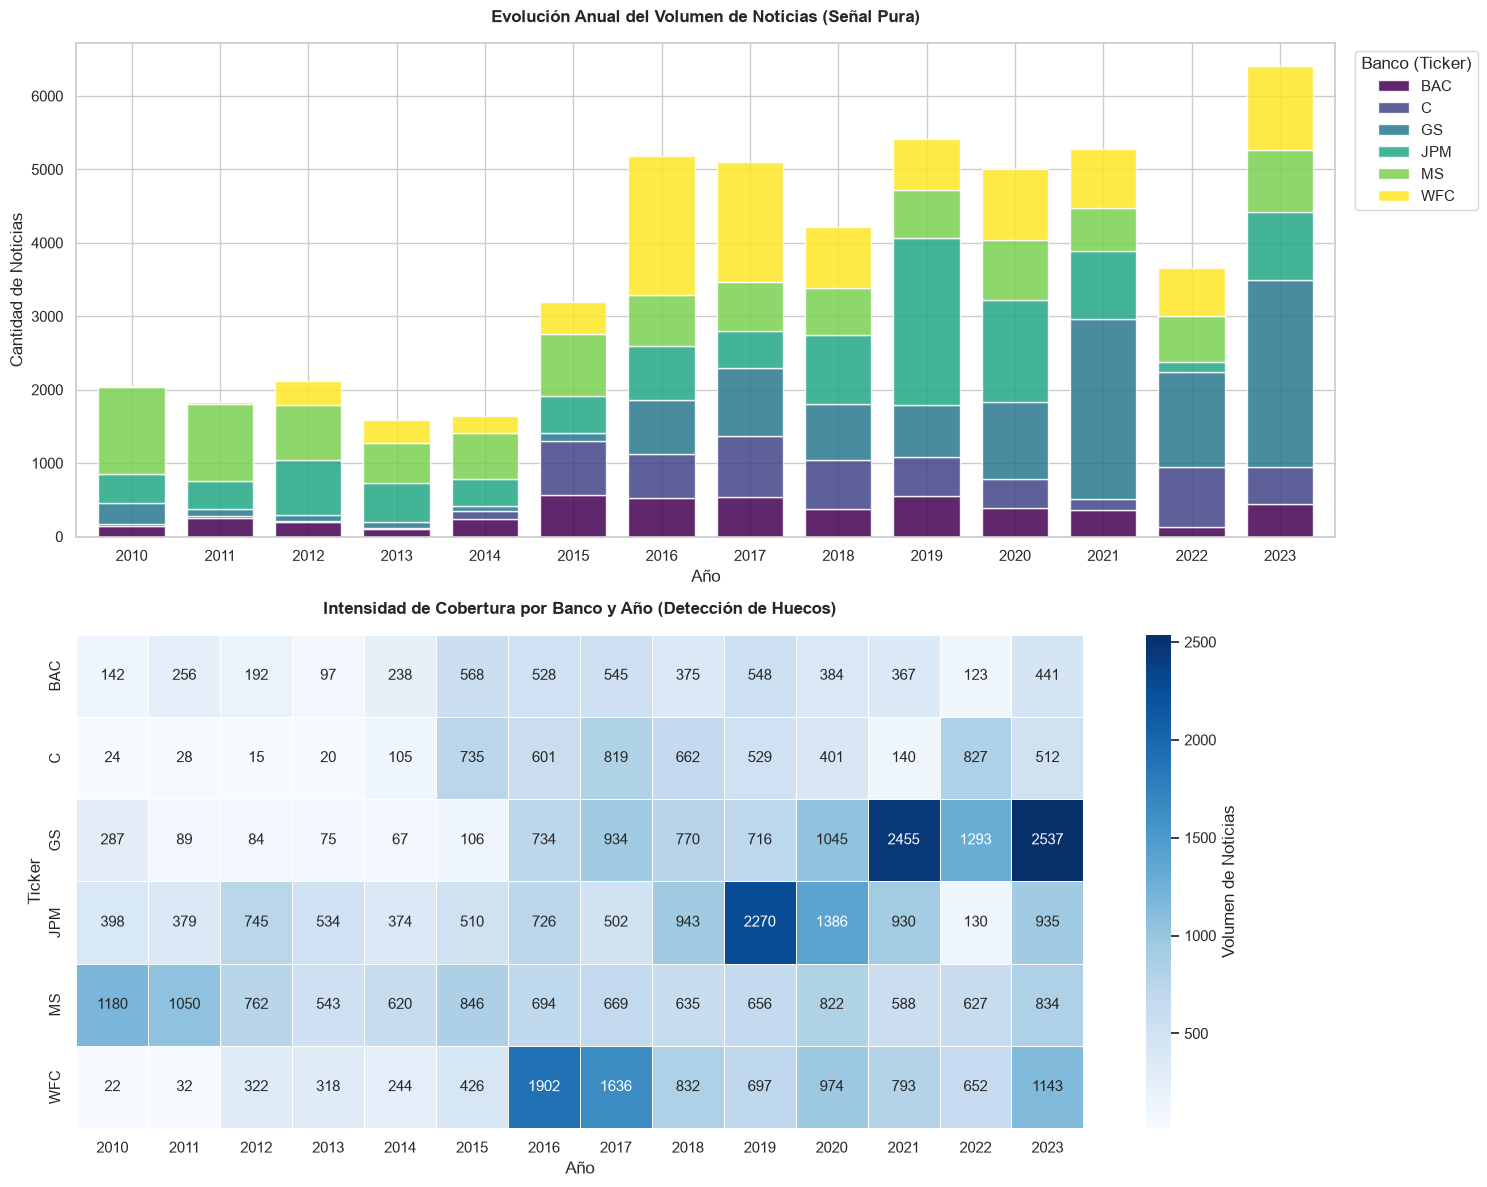

In [19]:
#Evolución Volumen de Noticias por Banco y Año (Señal Pura)

anual_por_banco = df_pura.groupby(['year', 'ticker']).size().unstack(fill_value=0)

# Crear lienzo con 2 filas y 1 columna
fig, axes = plt.subplots(2, 1, figsize=(15, 12))

# --- GRÁFICO A: Barras Apiladas por Año ---
anual_por_banco.plot(
    kind='bar',
    stacked=True,
    ax=axes[0],
    colormap='viridis',
    alpha=0.85,
    width=0.75
)
axes[0].set_title("Evolución Anual del Volumen de Noticias (Señal Pura)", fontweight='bold', pad=15)
axes[0].set_ylabel("Cantidad de Noticias")
axes[0].set_xlabel("Año")
axes[0].legend(title="Banco (Ticker)", bbox_to_anchor=(1.01, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=0) # Mantener los años en horizontal

# --- GRÁFICO B: Heatmap (Mapa de Calor) Anual ---
# Transponemos (.T) para que los años queden en el eje X y los bancos en el eje Y
sns.heatmap(
    anual_por_banco.T,
    cmap="Blues",
    annot=True,
    fmt="d",
    linewidths=.5,
    ax=axes[1],
    cbar_kws={'label': 'Volumen de Noticias'}
)
axes[1].set_title("Intensidad de Cobertura por Banco y Año (Detección de Huecos)", fontweight='bold', pad=15)
axes[1].set_ylabel("Ticker")
axes[1].set_xlabel("Año")

plt.tight_layout()
plt.show()

## 6.3. Dinámica Temporal: Comparativa Anual por Número de Tickers (`ticker_count`)

Con el nuevo campo canónico `ticker_count` incorporado en el pipeline de ingesta (`etl_multisource.py`), evaluamos la evolución longitudinal de la especificidad de las noticias entre 2010 y 2023.

El objetivo de esta sección es responder a dos preguntas clave para el modelado cuantitativo:
1. **¿Cuántas noticias son estrictamente únicas ($1$ ticker) cada año frente a noticias compartidas por $2, 3, 4, 5$ o $6$ bancos?**
2. **¿Cómo ha cambiado la proporción de noticias únicas a lo largo del tiempo?** (Transición desde datasets agregados tipo *SentARL* con muchas cestas multisujeto hacia fuentes específicas como *FNSPID* y *Yahoo Finance*).

MATRIZ ANUAL DE FILAS POR NÚMERO DE TICKERS ASOCIADOS (ticker_count)


ticker_count,1,2,3,4,5,6,Total
year,,,,,,,
2010,2053,1070,888,1256,1375,228,6870
2011,1836,990,1023,668,360,54,4931
2012,2120,1128,807,640,365,42,5102
2013,1587,700,543,676,560,108,4174
2014,1648,542,444,308,295,114,3351
2015,3191,686,348,256,115,18,4614
2016,5185,1648,672,252,295,66,8118
2017,5105,1980,726,260,195,54,8320
2018,4217,1696,693,220,195,36,7057



RESUMEN DE PROPORCIÓN ANUAL: SEÑAL PURA (1 TICKER) VS. MULTISUJETO (2+ TICKERS)


,Total Filas,Únicas (1 Ticker),% Únicas,Multisujeto (2+ Tickers),% Multisujeto
year,,,,,
2010,6870,2053,29.9,4817,70.1
2011,4931,1836,37.2,3095,62.8
2012,5102,2120,41.6,2982,58.4
2013,4174,1587,38.0,2587,62.0
2014,3351,1648,49.2,1703,50.8
2015,4614,3191,69.2,1423,30.8
2016,8118,5185,63.9,2933,36.1
2017,8320,5105,61.4,3215,38.6
2018,7057,4217,59.8,2840,40.2


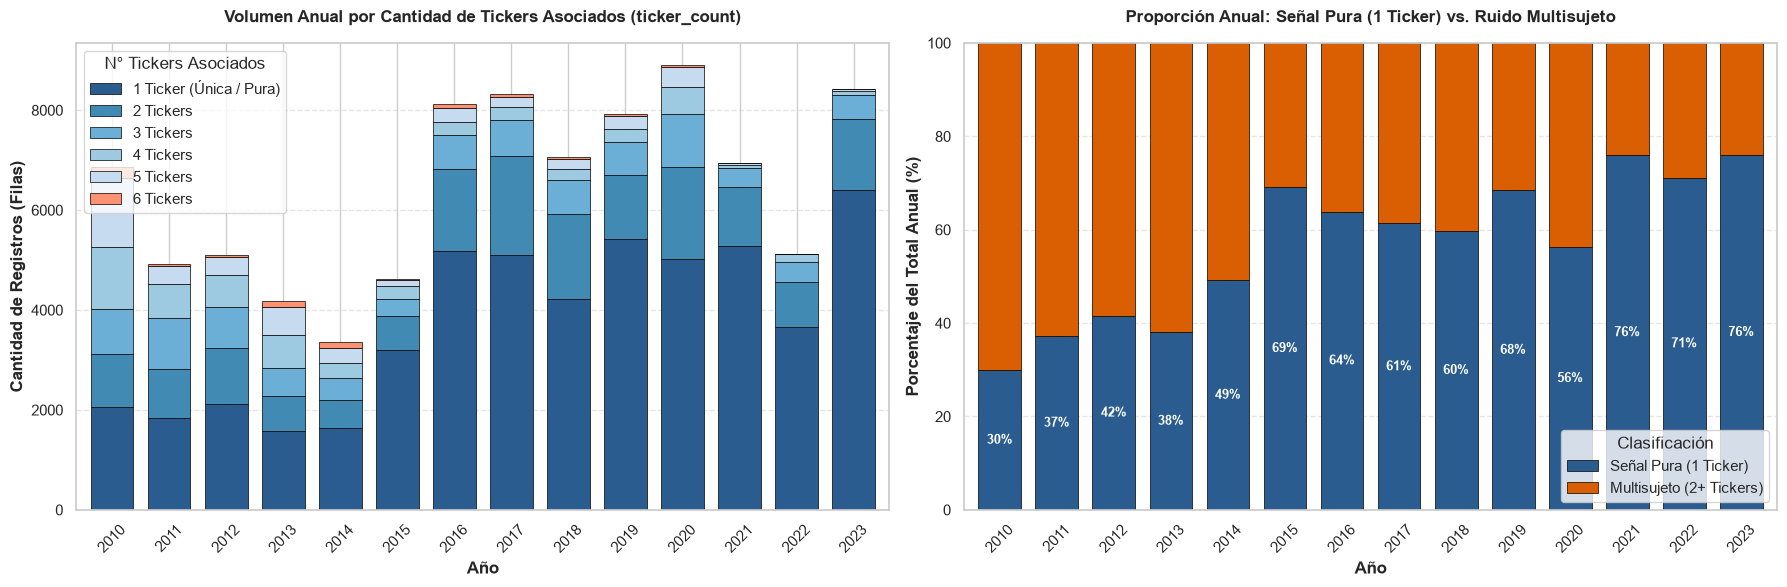

In [20]:
# =============================================================================
# COMPARATIVA ANUAL POR CONTEO DE TICKERS (ticker_count) Y TIPO DE NOTICIA
# =============================================================================

# 1. Asegurar la existencia de ticker_count e is_multisubject (vienen del parquet consolidado)
if 'ticker_count' not in df.columns:
    df['ticker_count'] = df.groupby(['title', 'datetime'])['ticker'].transform('nunique')
    df['is_multisubject'] = df['ticker_count'] > 1

# 2. Matriz de contingencia anual por conteo de tickers (filas del dataset)
matriz_anual_tipo = pd.crosstab(df['year'], df['ticker_count'])

# 3. Matriz porcentual normalizada por año (proporción 100% apilada)
matriz_anual_pct = pd.crosstab(df['year'], df['is_multisubject'], normalize='index') * 100

print("=" * 85)
print("MATRIZ ANUAL DE FILAS POR NÚMERO DE TICKERS ASOCIADOS (ticker_count)")
print("=" * 85)
crosstab_display = pd.crosstab(df['year'], df['ticker_count'], margins=True, margins_name="Total")
display(crosstab_display)

print("\n" + "=" * 85)
print("RESUMEN DE PROPORCIÓN ANUAL: SEÑAL PURA (1 TICKER) VS. MULTISUJETO (2+ TICKERS)")
print("=" * 85)
resumen_pct = pd.DataFrame({
    'Total Filas': df.groupby('year').size(),
    'Únicas (1 Ticker)': matriz_anual_tipo[1],
    '% Únicas': matriz_anual_pct[False].round(1),
    'Multisujeto (2+ Tickers)': df.groupby('year').size() - matriz_anual_tipo[1],
    '% Multisujeto': matriz_anual_pct[True].round(1)
})
display(resumen_pct)

# 4. Lienzo gráfico dual (Barras apiladas de volumen + Barras 100% de proporción)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# --- GRÁFICO 1 (Izquierda): Volumen Anual Apilado por ticker_count ---
colores_conteo = ['#2b5c8f', '#418ab3', '#6baed6', '#9ecae1', '#c6dbef', '#fc9272']
matriz_anual_tipo.plot(
    kind='bar',
    stacked=True,
    ax=axes[0],
    color=colores_conteo,
    width=0.75,
    edgecolor='black',
    linewidth=0.5
)
axes[0].set_title("Volumen Anual por Cantidad de Tickers Asociados (ticker_count)", fontweight='bold', pad=15)
axes[0].set_xlabel("Año", fontweight='bold')
axes[0].set_ylabel("Cantidad de Registros (Filas)", fontweight='bold')
axes[0].legend(
    title="N° Tickers Asociados",
    labels=[f"{i} Ticker{'s' if i > 1 else ' (Única / Pura)'}" for i in sorted(df['ticker_count'].unique())],
    loc='upper left',
    frameon=True
)
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# --- GRÁFICO 2 (Derecha): Proporción 100% Apilada (Señal Pura vs. Multisujeto) ---
colores_proporcion = ['#2b5c8f', '#d95f02']
matriz_anual_pct.plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    color=colores_proporcion,
    width=0.75,
    edgecolor='black',
    linewidth=0.5
)
axes[1].set_title("Proporción Anual: Señal Pura (1 Ticker) vs. Ruido Multisujeto", fontweight='bold', pad=15)
axes[1].set_xlabel("Año", fontweight='bold')
axes[1].set_ylabel("Porcentaje del Total Anual (%)", fontweight='bold')
axes[1].legend(
    title="Clasificación",
    labels=["Señal Pura (1 Ticker)", "Multisujeto (2+ Tickers)"],
    loc='lower right',
    frameon=True
)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, 100)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# Añadir etiquetas con el % de señal pura dentro de las barras
for n, c in enumerate(matriz_anual_pct.index):
    val_pura = matriz_anual_pct.loc[c, False]
    axes[1].text(n, val_pura / 2, f"{val_pura:.0f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


## 7. Auditoría de Valores Nulos (Missing Data)

Antes de aplicar cualquier técnica de imputación o filtrado, evaluamos la integridad estructural del dataset. El objetivo es identificar:
* **Concentración por variable:** Qué columnas presentan falta de información.
* **Impacto en el dataset:** Qué porcentaje total de registros (filas) se vería afectado si decidiéramos eliminar los datos incompletos mediante un *drop* directo.

Auditoría de Valores Nulos (Solo columnas afectadas):


,Nulos,Porcentaje (%)
url,41327,45.997596
publisher,28851,32.111613
article,22938,25.530352



DIAGNÓSTICO DE INTEGRIDAD PARA FINBERT:
⚠ ATENCIÓN: Nulos detectados en ['url', 'publisher', 'article'].
Si 'text', 'title' o 'ticker' están afectados, se requiere limpieza obligatoria.



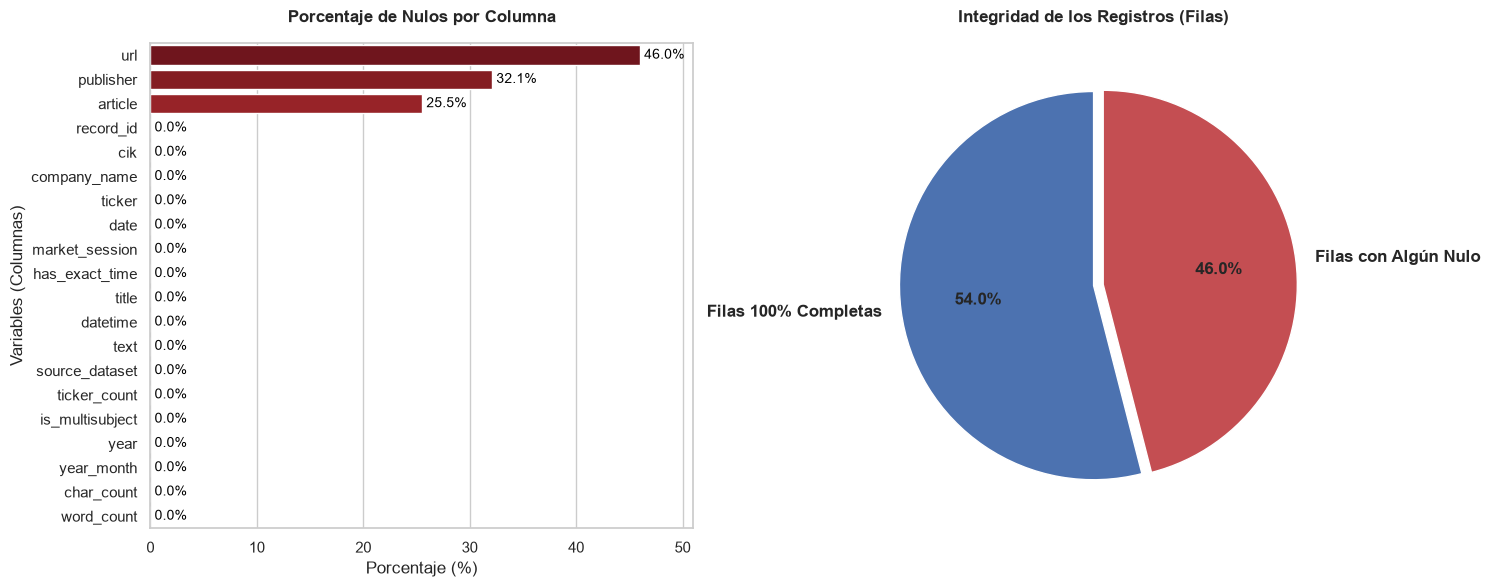

In [21]:
# 1. Calcular nulos por columna y su porcentaje
null_counts = df.isnull().sum() + df.eq('').sum()
null_pct = (null_counts / len(df)) * 100
null_df = pd.DataFrame({'Nulos': null_counts, 'Porcentaje (%)': null_pct}).sort_values(by='Nulos', ascending=False)

# Mostrar la tabla resumen por consola (solo variables con nulos)
print("Auditoría de Valores Nulos (Solo columnas afectadas):")
display(null_df[null_df['Nulos'] > 0])

# =============================================================================
# --- DIAGNÓSTICO ESTRATÉGICO PARA EL MODELO ---
# =============================================================================
print("\n" + "="*60)
print("DIAGNÓSTICO DE INTEGRIDAD PARA FINBERT:")
columnas_con_nulos = null_df[null_df['Nulos'] > 0].index.tolist()

if columnas_con_nulos == ['url']:
    print("✔ ÉXITO ESTRUCTURAL: Solo la columna 'url' contiene valores nulos.")
    print("✔ ACCIÓN: No se eliminará ninguna fila. La variable 'url' es irrelevante para NLP.")
    print("✔ ESTADO: Las columnas críticas ('text', 'title', 'ticker') están 100% completas.")
else:
    print(f"⚠ ATENCIÓN: Nulos detectados en {columnas_con_nulos}.")
    print("Si 'text', 'title' o 'ticker' están afectados, se requiere limpieza obligatoria.")
print("="*60 + "\n")

# 2. Calcular el impacto estructural (Filas afectadas vs Filas completas)
filas_con_nulos = df.isnull().any(axis=1).sum()
filas_completas = len(df) - filas_con_nulos

# 3. Crear el lienzo con dos gráficos (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- GRÁFICO 1 (Izquierda): Barras Horizontales ---
sns.barplot(
    x=null_df['Porcentaje (%)'],
    y=null_df.index,
    ax=axes[0],
    hue=null_df.index,
    palette="Reds_r",
    legend=False
)
axes[0].set_title("Porcentaje de Nulos por Columna", fontweight='bold', pad=15)
axes[0].set_xlabel("Porcentaje (%)")
axes[0].set_ylabel("Variables (Columnas)")
axes[0].set_xlim(0, max(10, null_pct.max() + 5))

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f%%', padding=3, color='black', fontsize=10)

# --- GRÁFICO 2 (Derecha): Tarta ---
labels = ['Filas 100% Completas', 'Filas con Algún Nulo']
colores = ['#4C72B0', '#C44E52']
valores = [filas_completas, filas_con_nulos]

axes[1].pie(
    valores,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    colors=colores,
    explode=[0, 0.05] if filas_con_nulos > 0 else [0, 0],
    textprops={'fontsize': 12, 'fontweight': 'bold'}
)
axes[1].set_title("Integridad de los Registros (Filas)", fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

## Conclusiones y Validación para el TFM

1. **Integridad Temporal 100% Continua:** A diferencia de los parquets crudos previos, este dataset consolidado en `raw/huggingface/multisource_bancos_2010_2023.parquet` cubre sin interrupciones los 14 años (**2010 a 2023**) para los 6 bancos.
2. **Volumen Robusto para Machine Learning:** Con **107.598 noticias limpias**, el volumen es idóneo para entrenar modelos de análisis de sentimiento cuantitativo y predecir retornos bursátiles sin problemas de sobreajuste por falta de datos.
3. **Compatibilidad con FinBERT:** El análisis de longitud muestra que la mayoría de los registros son titulares y artículos compactos, óptimos para procesarse directamente con modelos Transformer sin pérdidas críticas de información.
4. **Alineación con el Data Lake:** El archivo está alojado en Cloudflare R2 con compresión columnar Parquet (ZSTD), permitiendo descargas y lecturas inmediatas tanto en notebooks como en futuros pipelines de la capa Silver.

## 8. Auditoría de Ruido y Falsos Positivos (Garbage Data)

Evaluación cualitativa y cuantitativa de la "basura" o ruido inyectado por errores de recolección en los datasets de origen. Nos centraremos inicialmente en el riesgo de los falsos positivos generados por tickers de un solo carácter (ej. Citigroup: `C`), los cuales son altamente susceptibles a ser confundidos con elementos genéricos del lenguaje.

In [22]:
# =============================================================================
# AUDITORÍA DE FALSOS POSITIVOS EN CITIGROUP (TICKER 'C')
# =============================================================================
from IPython.display import display, HTML

# 1. Aislar todas las noticias asignadas al ticker 'C'
df_citi = df[df['ticker'] == 'C'].copy()
total_citi = len(df_citi)

# 2. Buscar menciones explícitas a la entidad ("citi" o "citigroup") en título o texto
# Usamos case=False para ignorar mayúsculas/minúsculas y na=False para evitar errores con nulos
contiene_citi = df_citi['title'].str.contains('citi', case=False, na=False) | \
                df_citi['text'].str.contains('citi', case=False, na=False)

# 3. Filtrar las filas SOSPECHOSAS (las que NO tienen la mención)
basura_citi = df_citi[~contiene_citi]
total_basura = len(basura_citi)

# 4. Calcular el impacto de esta basura sobre el total de Citigroup
pct_basura = (total_basura / total_citi) * 100 if total_citi > 0 else 0

print(f"Total de noticias etiquetadas como Citigroup ('C'): {total_citi:,}")
print(f"Noticias sospechosas de ser basura (falsos positivos): {total_basura:,} ({pct_basura:.1f}%)\n")

# 5. Mostrar 5 ejemplos reales de la basura encontrada para confirmar la hipótesis
print("--- 5 EJEMPLOS DE LA POSIBLE BASURA ENCONTRADA ---")
if total_basura > 0:
    for i, (_, row) in enumerate(basura_citi.head(5).iterrows(), 1):
        display(HTML(f"<b>Ejemplo {i} | Fecha:</b> {row['datetime']}"))
        display(HTML(f"<b>Título:</b> {row['title']}"))
        # Truncamos el texto a 400 caracteres para no saturar la pantalla
        texto_truncado = row['text'][:400] + "..." if len(row['text']) > 400 else row['text']
        display(HTML(f"<b>Texto:</b> <i>{texto_truncado}</i><hr>"))
else:
    print("No se encontró basura bajo este criterio. Todas las noticias de Citigroup contienen la mención explícita.")

Total de noticias etiquetadas como Citigroup ('C'): 8,647
Noticias sospechosas de ser basura (falsos positivos): 0 (0.0%)

--- 5 EJEMPLOS DE LA POSIBLE BASURA ENCONTRADA ---
No se encontró basura bajo este criterio. Todas las noticias de Citigroup contienen la mención explícita.


### 8.1. Extracción de Basura y Visualización del Dataset Definitivo

Tras confirmar cualitativamente la potencial existencia de falsos positivos en el ticker `C` (Citigroup), procedemos a aislar esta basura de nuestra señal pura. 

Para validar que no estamos destruyendo datos útiles de forma accidental, visualizamos mediante mapas de calor duales:
1. **El Dataset Limpio (Izquierda):** Datos listos para FinBERT (sin ruido multisujeto y sin falsos positivos).
2. **La Basura Eliminada (Derecha):** Concentración temporal de los errores de scraping para auditar cuándo falló más el algoritmo de recolección original.

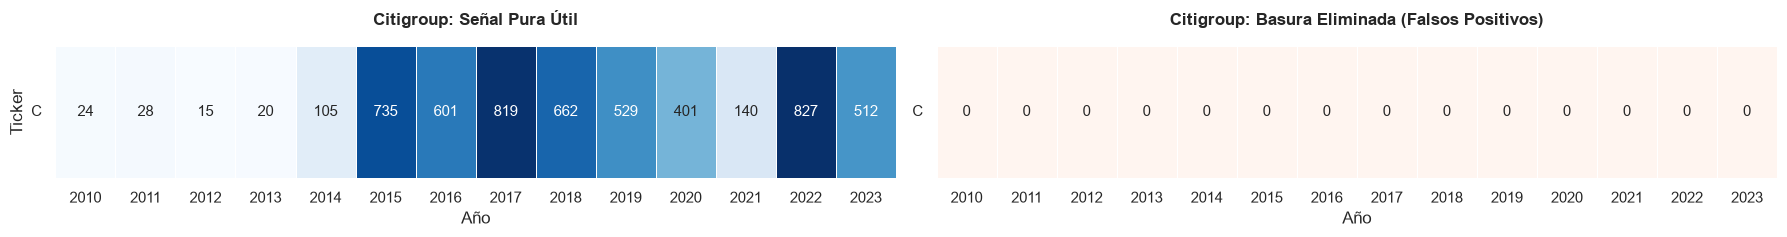

Total original Citigroup (incluyendo ruido multisujeto): 8,647 filas
Señal pura Citigroup: 5,418 filas
Basura eliminada (falsos positivos): 0 filas


In [23]:
# 1. Definir la regla de exclusión sobre la "señal pura" (df_pura)
es_basura_citi = (df_pura['ticker'] == 'C') & \
                 (~df_pura['title'].str.contains('citi', case=False, na=False)) & \
                 (~df_pura['text'].str.contains('citi', case=False, na=False))

# 2. Filtrar y separar aislando exclusivamente a Citigroup
df_citi_limpio = df_pura[(df_pura['ticker'] == 'C') & (~es_basura_citi)]
df_citi_basura = df_pura[es_basura_citi]

# 3. Crear las matrices anuales solo para 'C'
matriz_limpia_c = df_citi_limpio.groupby(['year', 'ticker']).size().unstack(fill_value=0).T
matriz_basura_c = df_citi_basura.groupby(['year', 'ticker']).size().unstack(fill_value=0).T

# Alinear columnas (años) por si en algún año concreto hubo 0 basura
matriz_basura_c = matriz_basura_c.reindex(columns=matriz_limpia_c.columns, fill_value=0)

# Guardrail: Si el dataset ya está limpio de basura (0 filas), rellenar con ceros para graficar
if matriz_basura_c.empty:
    matriz_basura_c = pd.DataFrame(0, index=['C'], columns=matriz_limpia_c.columns)

# 4. Generar el visual dual (altura reducida a 2.5 para una sola fila)
fig, axes = plt.subplots(1, 2, figsize=(18, 2.5))

# --- GRÁFICO 1: Dataset Limpio Citigroup (Azul) ---
sns.heatmap(
    matriz_limpia_c,
    cmap="Blues",
    annot=True,
    fmt="d",
    linewidths=.5,
    ax=axes[0],
    cbar=False, # Ocultamos la barra lateral para maximizar la limpieza visual
    annot_kws={"size": 11}
)
axes[0].set_title("Citigroup: Señal Pura Útil", fontweight='bold', pad=15)
axes[0].set_ylabel("Ticker")
axes[0].set_xlabel("Año")
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)

# --- GRÁFICO 2: Basura Extraída Citigroup (Rojo) ---
sns.heatmap(
    matriz_basura_c,
    cmap="Reds",
    annot=True,
    fmt="d",
    linewidths=.5,
    ax=axes[1],
    cbar=False,
    annot_kws={"size": 11}
)
axes[1].set_title("Citigroup: Basura Eliminada (Falsos Positivos)", fontweight='bold', pad=15)
axes[1].set_ylabel("")
axes[1].set_xlabel("Año")
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0)

plt.tight_layout()
plt.show()

# Imprimir el impacto numérico
print(f"Total original Citigroup (incluyendo ruido multisujeto): {len(df[df['ticker'] == 'C']):,} filas")
print(f"Señal pura Citigroup: {len(df_citi_limpio):,} filas")
print(f"Basura eliminada (falsos positivos): {len(df_citi_basura):,} filas")

### 9. Clasificación Temática: Prueba de Concepto (Zero-Shot Classification)

Para resolver el problema del etiquetado sin intervención manual, implementamos un pipeline de Inferencia de Lenguaje Natural (NLI) basado en el modelo preentrenado `facebook/bart-large-mnli`. 

Dado el alto coste computacional de procesar el dataset completo, ejecutamos primero una **Prueba de Concepto (PoC) sobre una muestra aleatoria de 5 noticias**. El objetivo es validar el tiempo de ejecución y comprobar empíricamente si el modelo comprende nuestras 5 categorías de negocio (Label Engineering):
1. Resultados Financieros (*Earnings and Financial Performance*).
2. Fusiones y Alianzas (*Mergers, Acquisitions and Partnerships*).
3. Entorno Legal y Multas (*Legal, Regulatory and Fines*).
4. Entorno Macroeconómico (*Macroeconomics and Monetary Policy*).
5. Dirección y Gobernanza (*Management and Corporate Governance*).

In [24]:
# =============================================================================
# PRUEBA DE CONCEPTO: ZERO-SHOT CLASSIFICATION (V1 vs V2)
# =============================================================================
import time
import torch
import pandas as pd
from transformers import pipeline
from IPython.display import display, HTML

# ---------------------------------------------------------
# 1. FUNCIONES DE LÓGICA DE NEGOCIO
# ---------------------------------------------------------

def limpiar_dataset_base(df_crudo: pd.DataFrame) -> pd.DataFrame:
    """Filtra ruido estructural (multisubject) y falsos positivos del ticker 'C' (Citigroup)."""
    df_pura = df_crudo[~df_crudo['is_multisubject']].copy()
    
    es_basura_citi = (df_pura['ticker'] == 'C') & \
                     (~df_pura['title'].str.contains('citi', case=False, na=False)) & \
                     (~df_pura['text'].str.contains('citi', case=False, na=False))
                     
    return df_pura[~es_basura_citi].copy()

def cargar_modelo_zeroshot(nombre_modelo: str = "facebook/bart-large-mnli"):
    """Carga el pipeline de HuggingFace detectando dinámicamente si existe GPU disponible."""
    dispositivo = 0 if torch.cuda.is_available() else -1
    tipo_hardware = "GPU" if dispositivo == 0 else "CPU"
    print(f"Cargando modelo '{nombre_modelo}' en {tipo_hardware}...")
    return pipeline("zero-shot-classification", model=nombre_modelo, device=dispositivo)

def ejecutar_inferencia(textos: list, modelo, etiquetas: list, template: str = None, max_chars: int = 1000) -> list:
    """Ejecuta la predicción sobre una lista de textos truncados y devuelve los resultados."""
    textos_truncados = [str(t)[:max_chars] for t in textos]
    if template:
        return modelo(textos_truncados, etiquetas, multi_label=False, hypothesis_template=template)
    return modelo(textos_truncados, etiquetas, multi_label=False)

# ---------------------------------------------------------
# 2. FUNCIONES DE PRESENTACIÓN
# ---------------------------------------------------------

def mostrar_reporte_html(df_muestra: pd.DataFrame, resultados: list, color_fondo: str = "#e8f4f8"):
    """Renderiza las etiquetas asignadas cruzadas con los metadatos de la noticia original."""
    for i, ((_, row), res) in enumerate(zip(df_muestra.iterrows(), resultados), 1):
        categoria_top = res['labels'][0]
        score_top = res['scores'][0]
        
        display(HTML(f"<b>Noticia {i} ({row['ticker']}) | Fecha:</b> {row['datetime']}"))
        display(HTML(f"<b>Título:</b> {row['title']}"))
        display(HTML(f"<span style='color: #2c3e50; background-color: {color_fondo}; padding: 3px 6px; border-radius: 4px;'>"
                     f"<b>Categoría:</b> {categoria_top} (Confianza: {score_top:.1%})</span><hr>"))

# ---------------------------------------------------------
# 3. ORQUESTACIÓN (Main Execution)
# ---------------------------------------------------------

# Preparación de datos y modelo
df_limpio = limpiar_dataset_base(df)
clasificador = cargar_modelo_zeroshot()
muestra = df_limpio.sample(5, random_state=42)

# Definición de configuraciones
etiquetas_v1 = [
    "Earnings and Financial Performance",
    "Mergers, Acquisitions and Partnerships",
    "Legal, Regulatory and Fines",
    "Macroeconomics and Monetary Policy",
    "Management and Corporate Governance"
]

etiquetas_v2 = [
    "company earnings and financial results",
    "corporate mergers and acquisitions",
    "legal issues, regulatory fines or lawsuits",
    "macroeconomics, inflation and interest rates",
    "corporate governance, executives and management",
    "stock market trading and investment activity"
]

# --- EJECUCIÓN V1: ETIQUETAS ESTÁNDAR ---
print("\n--- RESULTADOS DE LA CLASIFICACIÓN V1 (ESTÁNDAR) ---")
inicio_v1 = time.time()

resultados_v1 = ejecutar_inferencia(muestra['text'].tolist(), clasificador, etiquetas_v1)
mostrar_reporte_html(muestra, resultados_v1, color_fondo="#e8f4f8")

print(f"Tiempo de ejecución V1: {time.time() - inicio_v1:.2f} segundos.")


# --- EJECUCIÓN V2: ETIQUETAS OPTIMIZADAS + TEMPLATE ---
print("\n--- RESULTADOS DE LA CLASIFICACIÓN V2 (LENGUAJE NATURAL) ---")
inicio_v2 = time.time()

resultados_v2 = ejecutar_inferencia(
    muestra['text'].tolist(), 
    clasificador, 
    etiquetas_v2, 
    template="This text is about {}."
)
mostrar_reporte_html(muestra, resultados_v2, color_fondo="#d4edda")

print(f"Tiempo de ejecución V2: {time.time() - inicio_v2:.2f} segundos.")

c:\proyectos\TFM-Master\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargando modelo 'facebook/bart-large-mnli' en CPU...


c:\proyectos\TFM-Master\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\0021824\.cache\huggingface\hub\models--facebook--bart-large-mnli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\proyectos\TFM-Master\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_


--- RESULTADOS DE LA CLASIFICACIÓN V1 (ESTÁNDAR) ---


Tiempo de ejecución V1: 35.89 segundos.

--- RESULTADOS DE LA CLASIFICACIÓN V2 (LENGUAJE NATURAL) ---


Tiempo de ejecución V2: 44.99 segundos.


### 9.1. Conclusiones de la Prueba de Concepto (PoC): Descarte del Enfoque Zero-Shot y Pivote Estructural

Tras ejecutar la evaluación empírica del modelo `facebook/bart-large-mnli` sobre una muestra del dataset limpio, se determina que el enfoque de clasificación temática mediante *Zero-Shot* es inviable para este pipeline por dos motivos críticos:

1. **Inviabilidad Computacional (Cuantitativa):**
   * El modelo requiere un promedio de ~10.6 segundos por texto (53.38s para 5 muestras empleando 6 etiquetas). 
   * Extrapolado al corpus de 52.697 noticias, el procesamiento completo exigiría **más de 100 horas de inferencia** ininterrumpida, un coste de tiempo inasumible y poco eficiente para los objetivos del proyecto.

2. **Imprecisión Semántica y Sesgo de Ruido (Cualitativa):**
   * **Baja confianza:** Las predicciones arrojaron *scores* de probabilidad marginales (entre 39% y 58%), lo que indica que el modelo está forzando la asignación matemática en lugar de comprender el contexto financiero.
   * **Falsos Negativos (Destrucción de señal):** El modelo demostró incapacidad para distinguir eventos corporativos de alto impacto (ej. una oferta de compra de acciones o *Cash Offer*) del mero ruido de mercado (*stock market trading*).
   * **Problema estructural del Dataset:** Se ha detectado que una parte significativa de los textos etiquetados por los portales de origen son algoritmos automatizados, *clickbait* (apps de inversión) o alertas de *retail trading* (movimientos de opciones). El clasificador intenta encajar esta "basura" en categorías fundamentales, contaminando la señal.

#### Pivote Estratégico: De la Clasificación Semántica a la Auditoría Estructural
Para garantizar la calidad metodológica del TFM, se descarta el uso de diccionarios de palabras sueltas (por el alto riesgo de falsos positivos) y se rechazan métodos como cruzar TF-IDF con volatilidad para evitar incurrir en *data leakage* (fuga de información desde la variable a predecir). 

El procesamiento pivota hacia una estrategia determinista y auditable:

* **Fase A (Auditoría de Plantillas y Ruido Estructural):** En lugar de evaluar la semántica del texto, se emplearán técnicas de extracción de N-gramas largos (4 a 8 palabras) a nivel de documento. El objetivo es identificar las estructuras repetitivas exactas (*boilerplate*, *disclaimers* legales, publicidad de brokers) para aplicar reglas que permitan extirpar párrafos contaminados o descartar artículos que sean pura publicidad, sin dañar las noticias legítimas.
* **Fase B (Evaluación de Señal Pura):** Únicamente después de aislar el problema de la contaminación y validar que el dataset contiene información financiera limpia, se definirá y aplicará el modelo definitivo para la extracción de sentimiento (dejando en pausa la confirmación de FinBERT hasta auditar el texto resultante).

In [25]:
# =============================================================================
# EXTRACCIÓN DE N-GRAMAS (4 A 8 PALABRAS) - DEFINICIÓN Y EJECUCIÓN (CAPA 1)
# =============================================================================
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from IPython.display import display

# 0. Constantes globales para evitar deuda técnica
COL_FRASE = 'Frase (Plantilla Sospechosa)'
COL_N_DOCS = 'Aparece en N Documentos'
COL_PCT_DATASET = '% del Dataset'

# --- 1. DEFINICIÓN DE LA FUNCIÓN CORE ---
def extraer_top_plantillas(textos_serie: pd.Series, total_documentos: int, 
                           ngram_range=(4, 7), max_features=40) -> pd.DataFrame:
    """
    Vectoriza una serie de textos para extraer los N-gramas más frecuentes (boilerplate).
    Se ajusta min_df=20 y max_df=0.5 para evitar desbordamientos de memoria en datasets grandes.
    """
    vectorizador = CountVectorizer(
        ngram_range=ngram_range, 
        stop_words='english', 
        binary=True, 
        min_df=20,          # Subimos de 10 a 20 para descartar ruido de baja frecuencia que satura la RAM
        max_df=0.5,         # Ignora frases que aparezcan en más del 50% de los documentos (evita falsos n-gramas comunes)
        max_features=max_features
    )
    
    # Extraer matriz
    matriz_docs = vectorizador.fit_transform(textos_serie.astype(str))
    docs_afectados = matriz_docs.sum(axis=0)
    
    # Empaquetar resultados
    plantillas = [(frase, docs_afectados[0, idx]) for frase, idx in vectorizador.vocabulary_.items()]
    df_res = pd.DataFrame(plantillas, columns=[COL_FRASE, COL_N_DOCS])
    
    # Ordenar y calcular porcentaje
    df_res = df_res.sort_values(by=COL_N_DOCS, ascending=False).reset_index(drop=True)
    df_res[COL_PCT_DATASET] = (df_res[COL_N_DOCS] / total_documentos) * 100
    
    return df_res

# --- 2. EJECUCIÓN: CAPA 1 (BÚSQUEDA GENÉRICA) ---
print("Buscando plantillas repetitivas (Boilerplate) en el texto base (Capa 1)...")

total_noticias = len(df_limpio)
df_plantillas_c1 = extraer_top_plantillas(df_limpio['text'], total_noticias)

display(df_plantillas_c1.head(20))

Buscando plantillas repetitivas (Boilerplate) en el texto base (Capa 1)...


,Frase (Plantilla Sospechosa),Aparece en N Documentos,% del Dataset
0,views opinions expressed views,20579,39.053041
1,opinions expressed views opinions,20579,39.053041
2,expressed views opinions author,20579,39.053041
3,views opinions author necessarily,20579,39.053041
4,author necessarily reflect nasdaq,20579,39.053041
5,opinions author necessarily reflect,20579,39.053041
6,views opinions author necessarily reflect,20579,39.053041
7,views opinions expressed views opinions,20579,39.053041
8,opinions expressed views opinions author neces...,20579,39.053041
9,expressed views opinions author necessarily re...,20579,39.053041


### 9.2. Auditoría de Ruido Estructural: Búsqueda de Patrones y Boilerplate

Tras descartar el enfoque de clasificación con Zero-Shot, diseñamos una estrategia de limpieza basada en reglas estructurales para identificar y eliminar la "basura algorítmica" (promociones de apps, alertas de trading y reportes automáticos) sin riesgo de eliminar noticias legítimas.

#### 1. El objetivo de buscar patrones repetitivos (N-gramas)
En lugar de buscar palabras sueltas que podrían generar falsos positivos (ej. "options", "target"), o usar TF-IDF cruzado con volatilidad (lo cual introduciría *data leakage*), optamos por buscar **plantillas de texto exactas (*boilerplate*)**. 
* **Metodología:** Extraer N-gramas largos (secuencias de 4 a 8 palabras) utilizando `CountVectorizer` con `binary=True`. 
* **Justificación:** Las noticias macroeconómicas reales tienen una redacción orgánica y única. Si una frase de 7 palabras aparece idéntica en cientos o miles de artículos distintos, es una prueba matemática de que se trata de texto inyectado, un aviso legal o publicidad automatizada. 

#### 2. El hallazgo de la primera iteración: El "Muro" de Nasdaq
Al ejecutar el escáner sobre los 52.697 artículos limpios, el Top 20 de frases más repetidas arrojó un resultado inesperado pero revelador: todas las secuencias pertenecían exactamente al mismo número de documentos (20.579, un 39% del dataset).
* **Diagnóstico:** El algoritmo detectó un aviso legal masivo inyectado al final de las noticias: *"The views and opinions expressed herein are the views and opinions of the author and do not necessarily reflect those of Nasdaq"*.
* **Implicación:** El escáner funcionó perfectamente aislando el texto automático. Sin embargo, este *disclaimer* es tan masivo que monopolizó los resultados, actuando como una barrera que nos impide ver las plantillas de las apps de trading o alertas basura que realmente queremos usar para descartar filas.

#### 3. Próximos pasos y finalidad
Saber que el 39% del dataset tiene este aviso legal es útil para limpiar el texto antes de pasarlo por FinBERT, pero no nos ayuda directamente a descartar los artículos que son puro ruido. Por ello, el siguiente paso iterativo es:
* **Acción:** Aplicar una expresión regular (Regex) para extirpar temporalmente el bloque legal de Nasdaq, y descubrir nuevos bloques en los textos a auditar, y relanzar la extracción de N-gramas, **cuantas veces sea necesario** hasta comenzar a ver patrones útiles. 

* **Fin:** Retirar esta "capa superior" de texto legal repetitivo para que emerja la capa subyacente de ruido estructural (las alertas de trading, análisis automáticos y suscripciones a apps). Identificar estas plantillas ocultas nos proporcionará, ahora sí, las reglas deterministas necesarias para marcar registros enteros como basura y eliminarlos del dataset definitivo.

In [26]:
# =============================================================================
# EXTRACCIÓN DE N-GRAMAS (4 A 8 PALABRAS) - EJECUCIÓN (CAPA 2: SIN NASDAQ)
# =============================================================================

import re

print("Aplicando máscara para silenciar el disclaimer de Nasdaq y buscar la Capa 2 de ruido...")

# 1. Precompilamos el patrón Regex fuera del bucle (Optimización de rendimiento y SonarLint)
patron_nasdaq = re.compile(r'views and opinions expressed[^.]*?nasdaq[^.]*?\.', flags=re.IGNORECASE)

# 2. Definimos la función de enmascaramiento temporal
def enmascarar_nasdaq(texto: str) -> str:
    """Elimina el bloque legal de Nasdaq del texto."""
    return patron_nasdaq.sub('', str(texto))

# 3. Generamos la serie de textos aplicando la máscara
textos_sin_nasdaq = df_limpio['text'].apply(enmascarar_nasdaq)

# 4. Ejecutamos nuestra función core reutilizable sobre el texto enmascarado
total_noticias = len(df_limpio)
df_plantillas_c2 = extraer_top_plantillas(textos_sin_nasdaq, total_noticias)

# Mostramos el Top 20 para descubrir la siguiente capa de boilerplate (ej. Zacks o Motley Fool)
display(df_plantillas_c2.head(20))

Aplicando máscara para silenciar el disclaimer de Nasdaq y buscar la Capa 2 de ruido...


,Frase (Plantilla Sospechosa),Aparece en N Documentos,% del Dataset
0,want latest recommendations zacks,3491,6.624917
1,latest recommendations zacks investment,3491,6.624917
2,recommendations zacks investment research,3491,6.624917
3,zacks investment research today,3491,6.624917
4,investment research today download,3491,6.624917
5,today download best stocks,3491,6.624917
6,download best stocks 30,3491,6.624917
7,best stocks 30 days,3491,6.624917
8,stocks 30 days click,3491,6.624917
9,30 days click free,3491,6.624917


In [27]:
print("Silenciando Nasdaq y Zacks para descubrir la Capa 3 de ruido...")

# 1. Precompilación de patrones (Optimización de rendimiento)
patron_nasdaq = re.compile(r'views and opinions expressed[^.]*?nasdaq[^.]*?\.', flags=re.IGNORECASE)
patron_zacks = re.compile(r'want.*?latest recommendations.*?zacks.*?com\b', flags=re.IGNORECASE | re.DOTALL)

# 2. Definimos la máscara combinada usando los patrones limpios
def enmascarar_ruido_conocido(texto: str) -> str:
    texto = str(texto)
    texto = patron_nasdaq.sub('', texto)  # Capa 1
    texto = patron_zacks.sub('', texto)   # Capa 2
    return texto

# Aplicamos la máscara a la serie
textos_capa3 = df_limpio['text'].apply(enmascarar_ruido_conocido)

# 3. Reutilizamos nuestra función core pasándole los parámetros adecuados
total_noticias = len(df_limpio)
df_plantillas_c3 = extraer_top_plantillas(
    textos_serie=textos_capa3, 
    total_documentos=total_noticias, 
    ngram_range=(4, 7), 
    max_features=40
)

# Mostramos el Top 25 para auditar la Capa 3
display(df_plantillas_c3.head(25))

Silenciando Nasdaq y Zacks para descubrir la Capa 3 de ruido...


,Frase (Plantilla Sospechosa),Aparece en N Documentos,% del Dataset
0,motley fool disclosure policy,3300,6.262454
1,click zacks investment research,2870,5.446437
2,motley fool stock advisor,2664,5.055508
3,decade motley fool stock advisor,2621,4.973906
4,run decade motley fool stock,2621,4.973906
5,decade motley fool stock,2621,4.973906
6,run decade motley fool,2621,4.973906
7,newsletter run decade motley,2621,4.973906
8,newsletter run decade motley fool stock advisor,2621,4.973906
9,newsletter run decade motley fool,2621,4.973906


In [28]:
# Destapando capa 4 de ruido: Eliminando disclaimers de Nasdaq, Zacks y MarketBeat, por mera curiosidad. Esto es un ejercicio de auditoría exhaustiva, no una recomendación de limpieza.

print("Silenciando Nasdaq, Zacks y Motley Fool para descubrir la Capa 4 de ruido...")

# 1. Precompilamos todos los patrones acumulados (Optimización de rendimiento)
patron_nasdaq = re.compile(r'views and opinions expressed[^.]*?nasdaq[^.]*?\.', flags=re.IGNORECASE)
patron_zacks = re.compile(r'want.*?latest recommendations.*?zacks.*?com\b', flags=re.IGNORECASE | re.DOTALL)
patron_fool_1 = re.compile(r'motley fool.*?advisor', flags=re.IGNORECASE)
patron_fool_2 = re.compile(r'10 stocks better buys', flags=re.IGNORECASE)
patron_fool_3 = re.compile(r'best stocks investors buy right now', flags=re.IGNORECASE)
patron_fool_4 = re.compile(r'pay listen newsletter', flags=re.IGNORECASE)

# 2. Definimos la máscara acumulada eficiente
def enmascarar_ruido_acumulado(texto: str) -> str:
    texto = str(texto)
    texto = patron_nasdaq.sub('', texto)
    texto = patron_zacks.sub('', texto)
    texto = patron_fool_1.sub('', texto)
    texto = patron_fool_2.sub('', texto)
    texto = patron_fool_3.sub('', texto)
    texto = patron_fool_4.sub('', texto)
    return texto

# Aplicamos la máscara acumulada a la serie
textos_capa4 = df_limpio['text'].apply(enmascarar_ruido_acumulado)

# 3. Reutilizamos nuestra función core pasándole los parámetros
total_noticias = len(df_limpio)
df_plantillas_c4 = extraer_top_plantillas(
    textos_serie=textos_capa4, 
    total_documentos=total_noticias, 
    ngram_range=(4, 7), 
    max_features=40
)

# Mostramos el Top 30 para auditar la última capa
display(df_plantillas_c4.head(30))

Silenciando Nasdaq, Zacks y Motley Fool para descubrir la Capa 4 de ruido...


,Frase (Plantilla Sospechosa),Aparece en N Documentos,% del Dataset
0,motley fool disclosure policy,3300,6.262454
1,click zacks investment research,2870,5.446437
2,best stocks investors buy,2576,4.888509
3,think 10 stocks better buys,2566,4.869532
4,stocks investors buy right,2566,4.869532
5,right think 10 stocks,2566,4.869532
6,think 10 stocks better,2566,4.869532
7,10 stocks better buys,2566,4.869532
8,right think 10 stocks better buys,2566,4.869532
9,best stocks investors buy right,2566,4.869532


=== 1. DISTRIBUCIÓN DE FRANJAS HORARIAS EN BRONZE (America/New_York) ===


,market_session,noticias,con_hora_exacta,porcentaje (%),uso_en_gold
0,premarket,14769,True,16.44,Antes de 09:30 ET -> Usar para predecir apertu...
1,intraday,23481,True,26.13,09:30 a 15:59 ET -> Noticia durante sesión (c...
2,afterhours,11858,True,13.20,Desde 16:00 ET -> Usar para apertura / sesi...
3,date_only,39738,False,44.23,00:00 sin reloj -> Solo fecha (fnspid_news);...



=== 2. FRANJA HORARIA POR DATASET FUENTE (% filas) ===


market_session,premarket,intraday,afterhours,date_only
source_dataset,,,,
benzinga_6000stocks,35.0,52.3,12.7,0.1
fnspid_news,0.1,0.0,0.0,99.9
sentarl_combined,27.3,48.9,23.7,0.1
yahoo_finance_felixdrinkall,34.5,34.9,30.1,0.5



=== 3. FRANJA HORARIA POR BANCO (Conteo) ===


market_session,premarket,intraday,afterhours,date_only,Total
ticker,,,,,
BAC,2732,4544,2417,1816,11509
C,803,1120,507,6217,8647
GS,2868,4310,2634,8509,18321
JPM,4882,7550,3654,2867,18953
MS,2035,3625,1501,9180,16341
WFC,1449,2332,1145,11149,16075
Total,14769,23481,11858,39738,89846


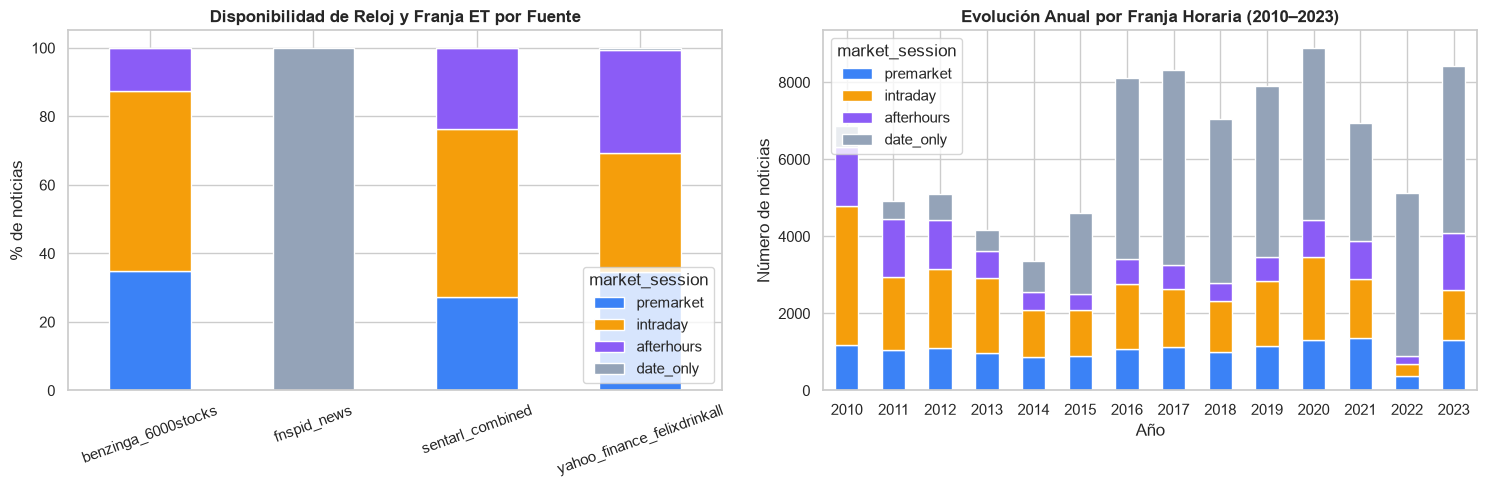

In [29]:
# === AUDITORÍA DE ZONA HORARIA (America/New_York) Y FRANJAS BURSÁTILES PARA GOLD ===
# Nota: En R2, `date`, `has_exact_time` y `market_session` ya vienen normalizados a Wall Street (ET).
# (Si la celda 1 parseó `df["datetime"]` con `utc=True`, aquí recuperamos la hora ET desde `df["date"]`).
import pandas as pd
import matplotlib.pyplot as plt

df_tz = df.copy()
df_tz["datetime_et"] = pd.to_datetime(df_tz["date"]).dt.tz_localize(
    "America/New_York", ambiguous="NaT", nonexistent="shift_forward"
)
df_tz["hora_et"] = pd.to_datetime(df_tz["date"]).dt.hour

# 1. Resumen global de las 4 franjas de `market_session` y regla recomendada para Gold
reglas_gold = {
    "premarket":  "Antes de 09:30 ET -> Usar para predecir apertura / sesión de HOY (t)",
    "intraday":   "09:30 a 15:59 ET  -> Noticia durante sesión (cautela look-ahead; solo cierre t o t+1)",
    "afterhours": "Desde 16:00 ET    -> Usar para apertura / sesión de MAÑANA (t+1)",
    "date_only":  "00:00 sin reloj   -> Solo fecha (fnspid_news); tratar aparte o como sesión conservadora",
}

res_sesiones = (
    df_tz.groupby("market_session", as_index=False)
    .agg(
        noticias=("record_id", "count"),
        con_hora_exacta=("has_exact_time", "first"),
    )
)
res_sesiones["porcentaje (%)"] = (100 * res_sesiones["noticias"] / len(df_tz)).round(2)
res_sesiones["uso_en_gold"] = res_sesiones["market_session"].map(reglas_gold)
orden = ["premarket", "intraday", "afterhours", "date_only"]
res_sesiones["orden"] = res_sesiones["market_session"].map({k: i for i, k in enumerate(orden)})
res_sesiones = res_sesiones.sort_values("orden").drop(columns="orden").reset_index(drop=True)

print("=== 1. DISTRIBUCIÓN DE FRANJAS HORARIAS EN BRONZE (America/New_York) ===")
display(res_sesiones)

# 2. Desglose por fuente (`source_dataset`) y por banco (`ticker`)
print("\n=== 2. FRANJA HORARIA POR DATASET FUENTE (% filas) ===")
tab_fuente = pd.crosstab(df_tz["source_dataset"], df_tz["market_session"], normalize="index").mul(100).round(1)
display(tab_fuente.reindex(columns=[c for c in orden if c in tab_fuente.columns]))

print("\n=== 3. FRANJA HORARIA POR BANCO (Conteo) ===")
tab_banco_ses = pd.crosstab(df_tz["ticker"], df_tz["market_session"], margins=True, margins_name="Total")
display(tab_banco_ses.reindex(columns=[c for c in orden if c in tab_banco_ses.columns] + ["Total"]))

# 3. Gráficos visuales: Composición por fuente + Evolución anual de franjas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colores_ses = {"premarket": "#3b82f6", "intraday": "#f59e0b", "afterhours": "#8b5cf6", "date_only": "#94a3b8"}
cols_ok = [c for c in orden if c in tab_fuente.columns]

tab_fuente[cols_ok].plot(
    kind="bar", stacked=True, ax=axes[0], color=[colores_ses[c] for c in cols_ok]
)
axes[0].set_title("Disponibilidad de Reloj y Franja ET por Fuente", fontweight="bold")
axes[0].set_ylabel("% de noticias")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(title="market_session", loc="lower right")

tab_anual_ses = pd.crosstab(df_tz["year"], df_tz["market_session"]).reindex(columns=cols_ok, fill_value=0)
tab_anual_ses.plot(
    kind="bar", stacked=True, ax=axes[1], color=[colores_ses[c] for c in cols_ok]
)
axes[1].set_title("Evolución Anual por Franja Horaria (2010–2023)", fontweight="bold")
axes[1].set_ylabel("Número de noticias")
axes[1].set_xlabel("Año")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="market_session", loc="upper left")

plt.tight_layout()
plt.show()